# 01 · EDA — Vehicle Type (Classification)
Predict Sedan (0), SUV (1) or Sports Car (2) from 20 measurements. Metric: accuracy. The private test set has extra measurement noise.

## Setup
Make `src/` importable and load the shared config (seed, paths).

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

# Make `src` importable: repo root locally, or an uploaded Kaggle dataset containing src/
for p in [Path.cwd(), *Path.cwd().parents, *(f.parent.parent for f in Path("/kaggle/input").glob("**/src/config.py"))]:
    if (p / "src" / "config.py").exists():
        sys.path.insert(0, str(p.resolve()))
        break

from src import config

Load the data.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats

from src.classification import preprocess as pp

TASK = "classification"
FIG_DIR = config.results_dir(TASK) / "figures"
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)

raw_train, raw_test, sample_sub = config.load(TASK)
FEATURES = [c for c in raw_train.columns if c not in (pp.ID, pp.TARGET)]
print("train", raw_train.shape, "| test", raw_test.shape, "| features", len(FEATURES))
print("missing values: train", raw_train.isna().sum().sum(), "| test", raw_test.isna().sum().sum())

train (10000, 22) | test (2500, 21) | features 20
missing values: train 0 | test 0


## Duplicates

In [3]:
dup = raw_train.duplicated(subset=FEATURES + [pp.TARGET], keep="first")
dup_features_only = raw_train.duplicated(subset=FEATURES, keep="first")
print(f"exact duplicates (features + label): {dup.sum():,}")
print(f"duplicates on features only:         {dup_features_only.sum():,}  (equal -> no copy has a different label)")
print("vehicle_id range of the copies:", raw_train.loc[dup, pp.ID].min(), "-", raw_train.loc[dup, pp.ID].max())

key = raw_train[FEATURES].astype(str).agg("|".join, axis=1)
original_id = key[dup].map(dict(zip(key[~dup], raw_train.loc[~dup, pp.ID])))
print("they copy rows with vehicle_id", original_id.min(), "-", original_id.max(), f"({original_id.nunique():,} different rows)")

exact duplicates (features + label): 2,500
duplicates on features only:         2,500  (equal -> no copy has a different label)
vehicle_id range of the copies: 7501 - 10000
they copy rows with vehicle_id 2 - 7499 (2,500 different rows)


- 2,500 exact duplicates (ids 7501–10000) with the same labels.

Class balance after removing duplicates.

In [4]:
X, y, X_test, test_ids, _ = pp.load_clean()
counts = y.value_counts().sort_index()
display(pd.DataFrame({"class": [pp.CLASS_NAMES[i] for i in counts.index], "rows": counts.values,
                      "share": (counts / len(y)).round(3).values}, index=counts.index))
print("clean train:", X.shape)

,class,rows,share
vehicle_class,,,
0,Sedan,2539,0.339
1,SUV,2490,0.332
2,Sports Car,2471,0.329


clean train: (7500, 20)


- 7,500 unique rows; classes are balanced (~33% each).

## Feature ranges

In [5]:
summary = X.describe().T[["mean", "std", "min", "50%", "max"]]
summary["whole numbers"] = [(X[c] % 1 == 0).all() for c in FEATURES]
display(summary.round(2))
print("whole-number features:", summary["whole numbers"].sum(), "of", len(FEATURES))

,mean,std,min,50%,max,whole numbers
engine_displacement_l,2.43,0.61,0.90,2.43,4.44,False
horsepower_hp,296.79,95.12,90.00,294.00,550.00,True
vehicle_weight_kg,1636.64,305.77,1100.00,1605.00,2600.00,True
wheelbase_mm,2778.26,172.42,2400.00,2757.00,3300.00,True
vehicle_length_mm,4659.47,366.35,3900.00,4622.00,5400.00,True
vehicle_width_mm,1836.51,117.79,1650.00,1824.00,2050.00,True
vehicle_height_mm,1528.91,145.62,1250.00,1530.00,2050.00,True
fuel_tank_capacity_l,61.10,14.48,35.00,60.00,90.00,True
city_fuel_efficiency_kmpl,11.61,2.55,7.00,11.55,20.87,False
highway_fuel_efficiency_kmpl,15.85,2.50,9.00,15.83,24.07,False


whole-number features: 14 of 20


- Feature scales differ by 10⁴, so logistic regression needs standardisation.

## Feature distributions by class

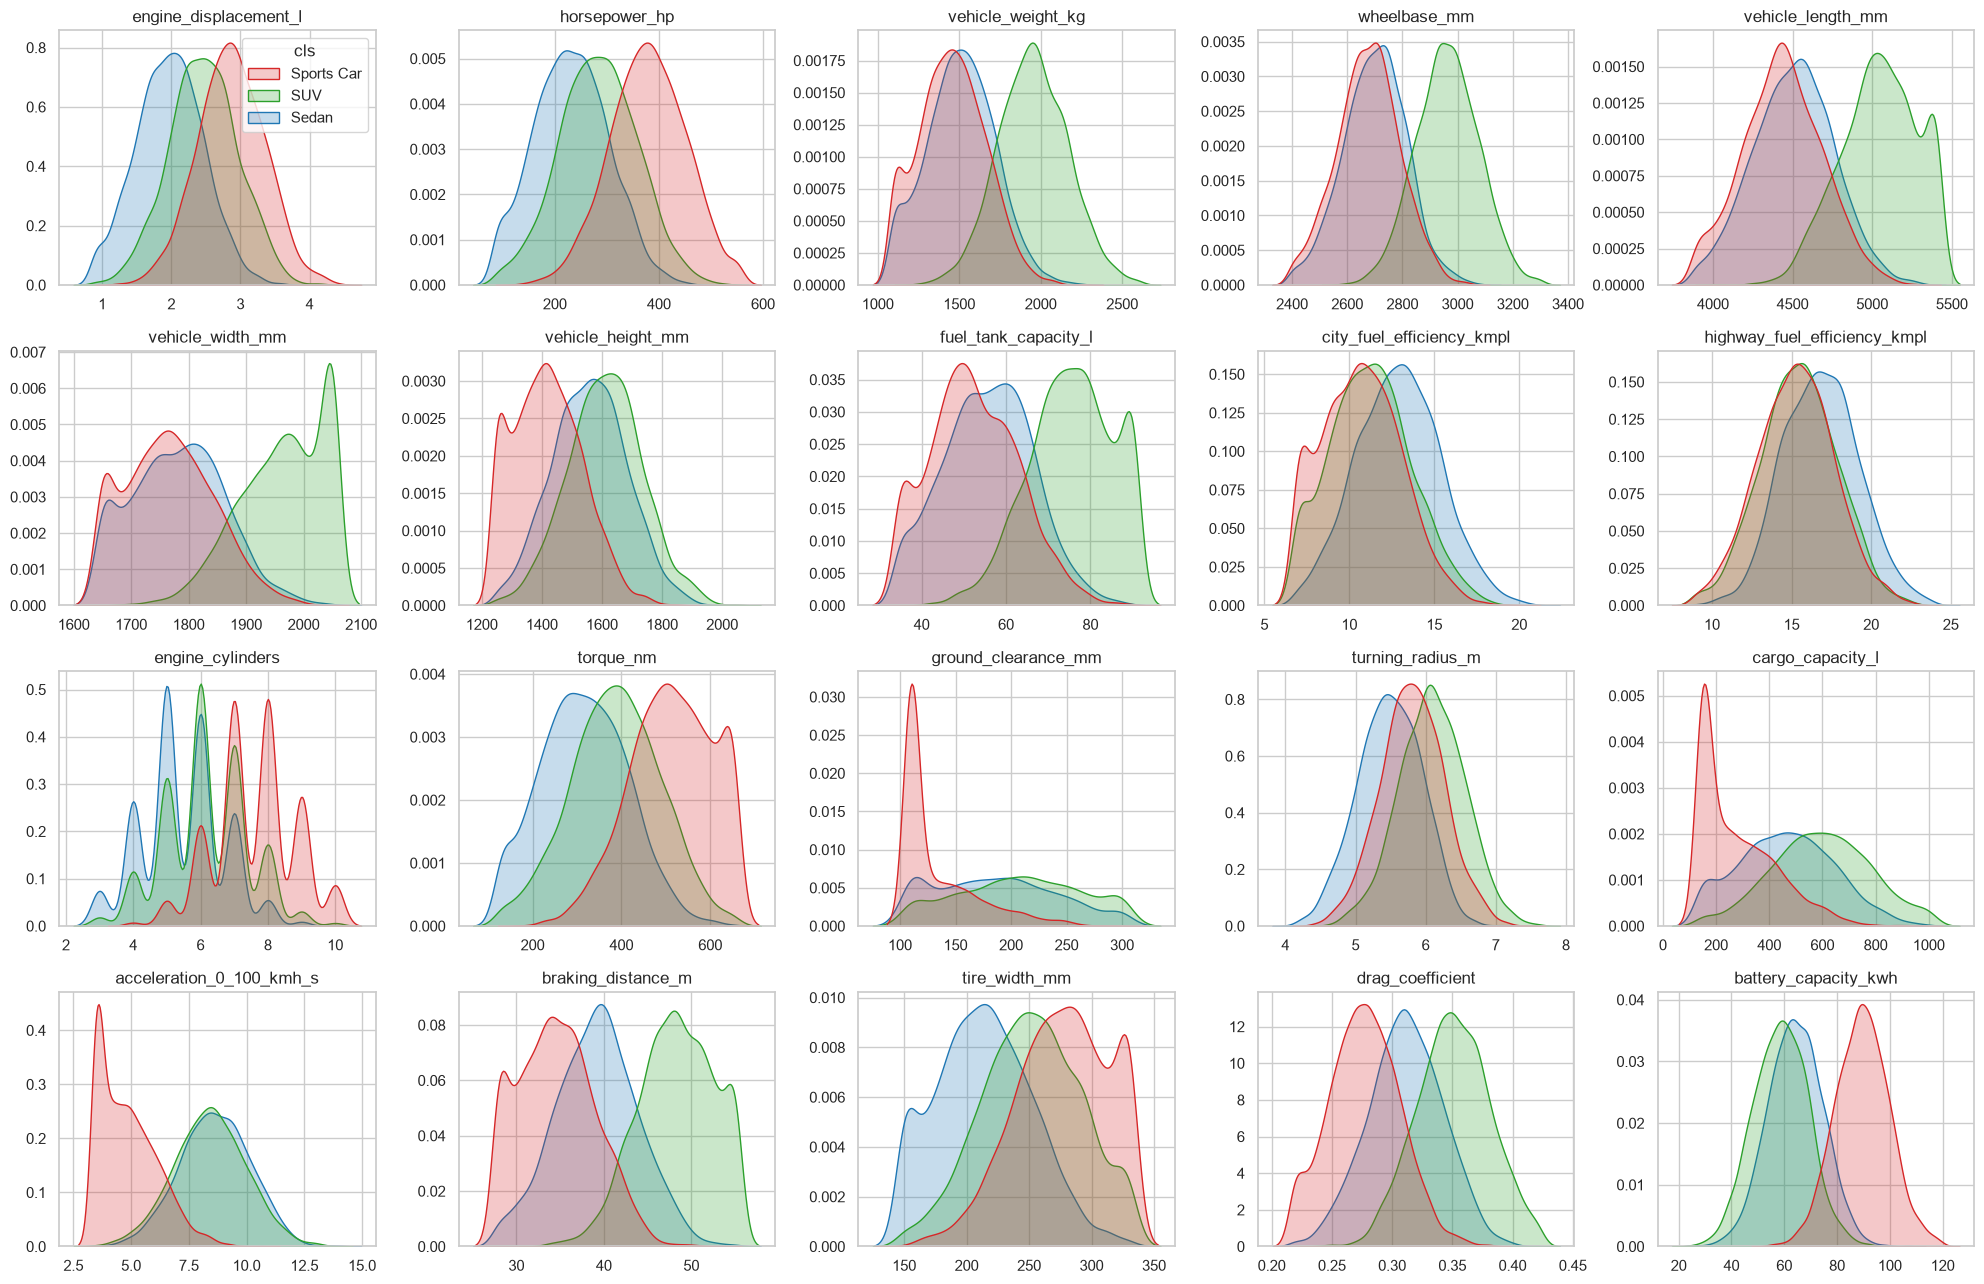

In [6]:
palette = {"Sedan": "tab:blue", "SUV": "tab:green", "Sports Car": "tab:red"}
named = X.assign(cls=y.map(pp.CLASS_NAMES))
fig, axes = plt.subplots(4, 5, figsize=(20, 13))
for ax, col in zip(axes.flat, FEATURES):
    sns.kdeplot(data=named, x=col, hue="cls", palette=palette, common_norm=False, fill=True, alpha=0.25, ax=ax, legend=(col == FEATURES[0]))
    ax.set(title=col, xlabel="", ylabel="")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_2_3_class_distributions.png", dpi=110, bbox_inches="tight")
plt.show()

Median of each feature per class.

In [7]:
medians = X.groupby(y.map(pp.CLASS_NAMES)).median().T[["Sedan", "SUV", "Sports Car"]]
display(medians.round(2))

vehicle_class,Sedan,SUV,Sports Car
engine_displacement_l,1.97,2.46,2.86
horsepower_hp,230.00,282.00,380.00
vehicle_weight_kg,1507.00,1950.00,1452.00
wheelbase_mm,2703.00,2962.00,2677.00
vehicle_length_mm,4513.00,5052.00,4433.00
vehicle_width_mm,1782.00,1972.00,1763.00
vehicle_height_mm,1558.00,1611.00,1412.00
fuel_tank_capacity_l,56.00,76.00,51.00
city_fuel_efficiency_kmpl,12.89,11.18,10.64
highway_fuel_efficiency_kmpl,16.81,15.48,15.27


## Accuracy of each feature on its own (depth-3 tree)

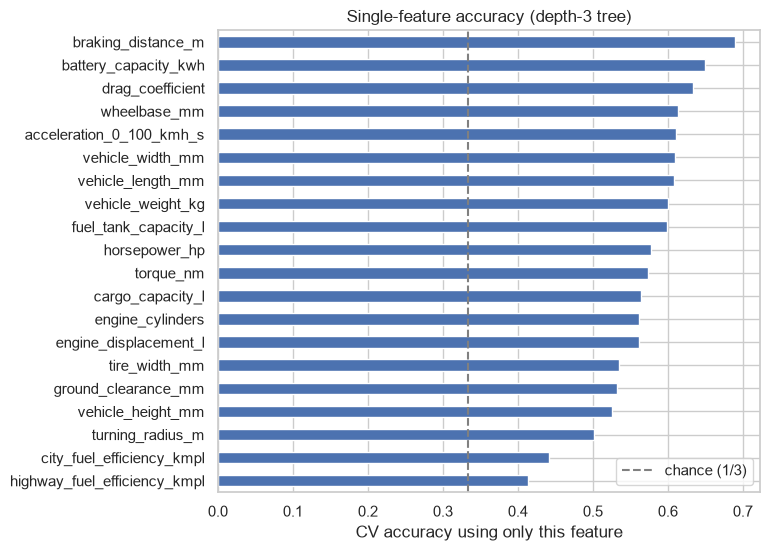

braking_distance_m          0.689
battery_capacity_kwh        0.649
drag_coefficient            0.633
wheelbase_mm                0.614
acceleration_0_100_kmh_s    0.611


In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(config.N_FOLDS, shuffle=True, random_state=config.SEED)
single = pd.Series({c: cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=config.SEED), X[[c]], y, cv=cv).mean()
                    for c in FEATURES}).sort_values()
ax = single.plot.barh(figsize=(7, 6))
ax.axvline(1 / 3, color="grey", ls="--", label="chance (1/3)")
ax.set(xlabel="CV accuracy using only this feature", title="Single-feature accuracy (depth-3 tree)")
ax.legend()
plt.savefig(FIG_DIR / "eda_2_4_single_feature.png", dpi=110, bbox_inches="tight")
plt.show()
print(single.sort_values(ascending=False).round(3).head(5).to_string())

- The best single feature (braking distance) reaches only 0.69.

## Correlation

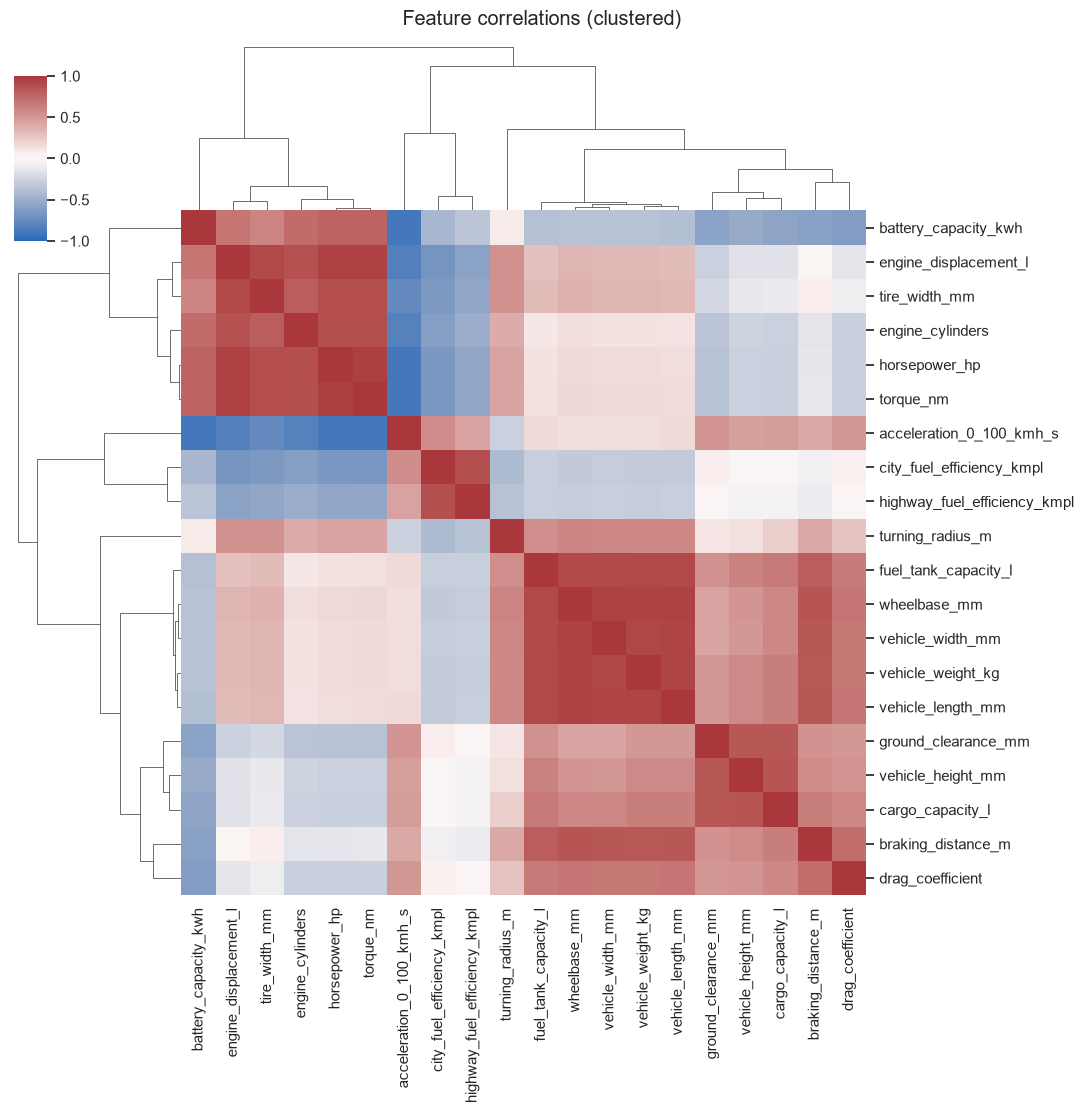

pairs with |r| > 0.7: 39 of 190
horsepower_hp          torque_nm            0.959
engine_displacement_l  torque_nm            0.952
wheelbase_mm           vehicle_width_mm     0.952
engine_displacement_l  horsepower_hp        0.950
wheelbase_mm           vehicle_length_mm    0.949
vehicle_weight_kg      wheelbase_mm         0.945
vehicle_length_mm      vehicle_width_mm     0.937
vehicle_weight_kg      vehicle_length_mm    0.935


In [9]:
corr = X.corr()
g = sns.clustermap(corr, cmap="vlag", vmin=-1, vmax=1, figsize=(11, 11), annot=False, cbar_pos=(0.02, 0.8, 0.03, 0.15))
g.fig.suptitle("Feature correlations (clustered)", y=1.01)
g.savefig(FIG_DIR / "eda_2_5_correlation.png", dpi=110, bbox_inches="tight")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("pairs with |r| > 0.7:", (pairs.abs() > 0.7).sum(), "of", len(pairs))
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(3).to_string())

Correlation within each class.

In [10]:
for k, name in pp.CLASS_NAMES.items():
    ck = X[y == k].corr()
    pk = ck.where(np.triu(np.ones(ck.shape), 1).astype(bool)).stack()
    top = pk.abs().idxmax()
    print(f"{name:10s}: pairs with |r| > 0.5: {(pk.abs() > 0.5).sum():3d} of {len(pk)}, strongest {top[0]} ~ {top[1]} ({pk[top]:.2f})")

Sedan     : pairs with |r| > 0.5:  73 of 190, strongest engine_displacement_l ~ torque_nm (0.94)
SUV       : pairs with |r| > 0.5:  75 of 190, strongest engine_displacement_l ~ torque_nm (0.94)
Sports Car: pairs with |r| > 0.5:  73 of 190, strongest engine_displacement_l ~ horsepower_hp (0.94)


- Features are strongly correlated, even within each class (size and power groups).

## PCA

cumulative explained variance: [0.411 0.795 0.854 0.894 0.918 0.934]

largest loadings:
PC1 ['vehicle_length_mm', 'vehicle_weight_kg', 'fuel_tank_capacity_l', 'wheelbase_mm']
PC2 ['engine_displacement_l', 'torque_nm', 'horsepower_hp', 'tire_width_mm']


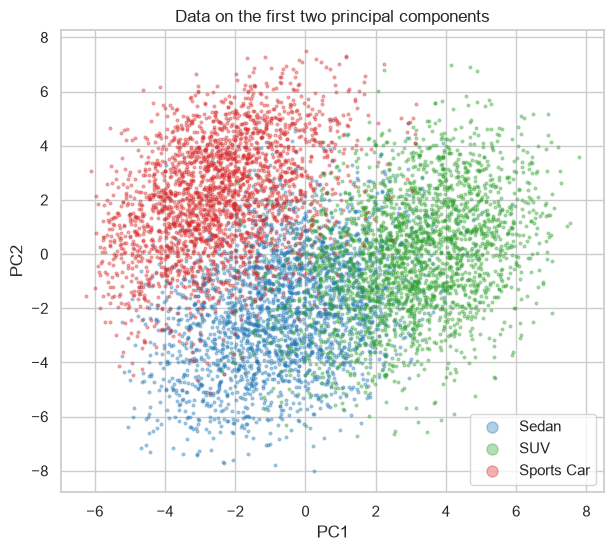

In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca = PCA().fit(StandardScaler().fit_transform(X))
print("cumulative explained variance:", pca.explained_variance_ratio_.cumsum()[:6].round(3))
pcs = pca.transform(StandardScaler().fit_transform(X))[:, :2]
loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
print("\nlargest loadings:")
for pc in loadings:
    print(pc, loadings[pc].abs().sort_values(ascending=False).head(4).index.tolist())

fig, ax = plt.subplots(figsize=(7, 6))
for k, name in pp.CLASS_NAMES.items():
    m = (y == k).to_numpy()
    ax.scatter(pcs[m, 0], pcs[m, 1], s=4, alpha=0.35, label=name, color=palette[name])
ax.set(xlabel="PC1", ylabel="PC2", title="Data on the first two principal components")
ax.legend(markerscale=4)
plt.savefig(FIG_DIR / "eda_2_6_pca.png", dpi=110, bbox_inches="tight")
plt.show()

- Two components (size, power) carry 80% of the variance; class boundaries look roughly linear.

## Train vs public test

In [12]:
cmp = pd.DataFrame({
    "std ratio (test/train)": raw_test[FEATURES].std() / X.std(),
    "mean shift (in train std)": (raw_test[FEATURES].mean() - X.mean()) / X.std(),
    "KS p-value": [stats.ks_2samp(X[c], raw_test[c]).pvalue for c in FEATURES],
})
display(cmp.sort_values("KS p-value").round(4).head(6))
print("std ratio range:", cmp["std ratio (test/train)"].min().round(3), "-", cmp["std ratio (test/train)"].max().round(3))
print("whole-number features in test:", sum((raw_test[c] % 1 == 0).all() for c in FEATURES), "(train:", summary["whole numbers"].sum(), ")")

,std ratio (test/train),mean shift (in train std),KS p-value
ground_clearance_mm,1.0049,0.0188,0.0000
cargo_capacity_l,0.9758,-0.0015,0.0067
city_fuel_efficiency_kmpl,1.0158,-0.0405,0.0514
engine_displacement_l,1.0385,0.0273,0.1107
tire_width_mm,1.0268,0.0235,0.1491
vehicle_length_mm,0.9918,0.0304,0.2396


std ratio range: 0.976 - 1.038
whole-number features in test: 14 (train: 14 )


- Spreads match (std ratio 0.98–1.04): no large noise in the public test.

Share of rows at the floor value: train, test and train + simulated noise.

In [13]:
rng = np.random.default_rng(config.SEED)

def floor_share_after_noise(col, k, reps=20):
    lo, hi, sd = X[col].min(), X[col].max(), X[col].std()
    decimals = 0 if summary.loc[col, "whole numbers"] else 2
    return np.mean([(np.round(np.clip(X[col] + rng.normal(0, k * sd, len(X)), lo, hi), decimals) == lo).mean()
                    for _ in range(reps)])

spiky = ["ground_clearance_mm", "cargo_capacity_l", "acceleration_0_100_kmh_s", "vehicle_width_mm",
         "fuel_tank_capacity_l", "vehicle_height_mm", "vehicle_weight_kg"]
floor = pd.DataFrame({
    "floor value": [X[c].min() for c in spiky],
    "train share at floor": [(X[c] == X[c].min()).mean() for c in spiky],
    "test share at floor": [(raw_test[c] == X[c].min()).mean() for c in spiky],
    "train + noise k=0.05": [floor_share_after_noise(c, 0.05) for c in spiky],
    "train + noise k=0.1": [floor_share_after_noise(c, 0.1) for c in spiky],
}, index=spiky)
display(floor.round(3))

,floor value,train share at floor,test share at floor,train + noise k=0.05,train + noise k=0.1
ground_clearance_mm,110.0,0.231,0.174,0.137,0.132
cargo_capacity_l,150.0,0.126,0.087,0.069,0.072
acceleration_0_100_kmh_s,3.5,0.071,0.058,0.039,0.043
vehicle_width_mm,1650.0,0.055,0.040,0.032,0.034
fuel_tank_capacity_l,35.0,0.035,0.019,0.028,0.025
vehicle_height_mm,1250.0,0.033,0.024,0.019,0.020
vehicle_weight_kg,1100.0,0.030,0.015,0.017,0.019


- Floor spikes are smaller in test, which suggests mild noise.

## Simulated noise: logistic regression vs unpruned tree

,logistic regression,unpruned tree
k,,
0.0,0.894,0.824
0.1,0.892,0.815
0.2,0.886,0.803
0.3,0.873,0.775
0.5,0.850,0.703


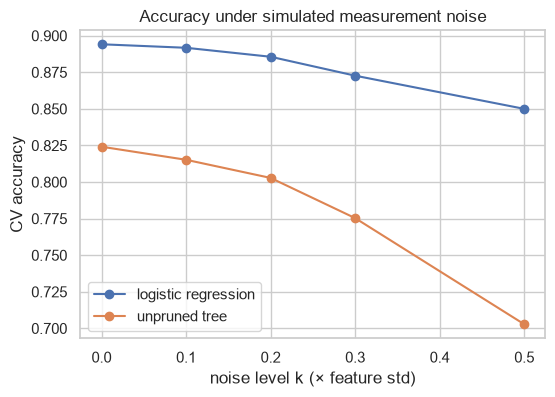

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from src import evaluate

ks = [0, 0.1, 0.2, 0.3, 0.5]
preview = pd.DataFrame({
    "logistic regression": evaluate.noise_curve(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), X, y, TASK, ks)["mean"],
    "unpruned tree": evaluate.noise_curve(DecisionTreeClassifier(random_state=config.SEED), X, y, TASK, ks)["mean"],
})
display(preview.round(3))
ax = preview.plot(marker="o", figsize=(6, 4))
ax.set(xlabel="noise level k (× feature std)", ylabel="CV accuracy", title="Accuracy under simulated measurement noise")
plt.savefig(FIG_DIR / "eda_2_8_noise_preview.png", dpi=110, bbox_inches="tight")
plt.show()

- At k = 0.3 logistic loses 2.1 points and the tree 4.9, so models are compared with noisy CV.